# AeroMind AI: Air Quality Predition System

## Project Goal: The goal of this project is to predict Air Quality Index(AQI) categories using weather and pollutant data. The project compares multiple Machine Learning models and uses Explainable AI techniques to understant prediction behavior.

## Technologies Used
- Python
- Pandas
- Numpy
- Matplotlib
- Scikit-Learn
- XGBoost
- SHAP
- FastAPI
- React

In [1]:
# Importing Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import(
    train_test_split,
    cross_val_score,
    StratifiedKFold
)

from sklearn.metrics import(
    accuracy_score,
    confusion_matrix,
    classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

import pickle

In [2]:
# Load dataset
df = pd.read_csv(r"C:\Users\soham\Documents\Program(SOHAM)\AeroMind AI\dataset\GlobalWeatherRepository.csv")

print("Dataset Loaded Successfully")

Dataset Loaded Successfully


In [3]:
# Dataset information
print(df.info())
print("\nShape:")
print(df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 141118 entries, 0 to 141117
Data columns (total 41 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   country                       141118 non-null  object 
 1   location_name                 141118 non-null  object 
 2   latitude                      141118 non-null  float64
 3   longitude                     141118 non-null  float64
 4   timezone                      141118 non-null  object 
 5   last_updated_epoch            141118 non-null  int64  
 6   last_updated                  141118 non-null  object 
 7   temperature_celsius           141118 non-null  float64
 8   temperature_fahrenheit        141118 non-null  float64
 9   condition_text                141118 non-null  object 
 10  wind_mph                      141118 non-null  float64
 11  wind_kph                      141118 non-null  float64
 12  wind_degree                   141118 non-nul

In [4]:
# AQI Distribution
print(
    df["air_quality_us-epa-index"].value_counts()
)

air_quality_us-epa-index
1    76245
2    44083
3    11264
4     7895
5     1187
6      444
Name: count, dtype: int64


In [5]:
# Selecting important features
features = [
    'temperature_celsius',
    'humidity',
    'wind_kph',
    'pressure_mb',
    'precip_mm',
    'air_quality_PM2.5',
    'air_quality_PM10',
    'air_quality_Carbon_Monoxide',
    'air_quality_Nitrogen_dioxide',
    'air_quality_Ozone',
    'air_quality_Sulphur_dioxide'
]

# Output column- predict
target = 'air_quality_us-epa-index'

In [6]:
# Missing values
print(df[features].isnull().sum())

temperature_celsius             0
humidity                        0
wind_kph                        0
pressure_mb                     0
precip_mm                       0
air_quality_PM2.5               0
air_quality_PM10                0
air_quality_Carbon_Monoxide     0
air_quality_Nitrogen_dioxide    0
air_quality_Ozone               0
air_quality_Sulphur_dioxide     0
dtype: int64


In [7]:
# Input Features
X= df[features]

# Target Variable
y= df[target]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (141118, 11)
Target Shape: (141118,)


In [8]:
# Train-Test split
x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

Training Data: (112894, 11)
Testing Data: (28224, 11)


In [9]:

# STEP 1: Validate the Dataset and Train-Test Split

import pandas as pd
import numpy as np

# 1. Check dataset size
print("========== DATASET ==========")
print("Rows:", len(df))
print("Columns:", len(df.columns))

# 2. Check target distribution
print("\n========== TARGET DISTRIBUTION ==========")

target_counts = df[target].value_counts().sort_index()
target_percentages = (
    df[target].value_counts(normalize=True).sort_index() * 100
)

distribution = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages.round(2)
})

print(distribution)

# 3. Check missing values
print("\n========== MISSING VALUES ==========")
print("Missing target values:", df[target].isna().sum())
print("Missing feature values:", df[features].isna().sum().sum())

# 4. Check exact duplicate rows
print("\n========== DUPLICATES ==========")
print("Exact duplicate dataset rows:", df.duplicated().sum())

feature_target_columns = features + [target]

print(
    "Duplicate feature-target combinations:",
    df.duplicated(subset=feature_target_columns).sum()
)

# 5. Check whether the same feature-target combination
# appears in both training and testing data
train_data = df.loc[x_train.index, feature_target_columns]
test_data = df.loc[x_test.index, feature_target_columns]

train_keys = set(
    map(tuple, train_data.to_numpy())
)

test_keys = set(
    map(tuple, test_data.to_numpy())
)

overlap = train_keys.intersection(test_keys)

print("\n========== TRAIN-TEST OVERLAP ==========")
print("Unique combinations in training data:", len(train_keys))
print("Unique combinations in testing data:", len(test_keys))
print("Combinations present in BOTH sets:", len(overlap))

# 6. Confirm all six classes are represented
print("\n========== CLASS CHECK ==========")
print("Classes in dataset:", sorted(df[target].unique()))
print("Classes in training:", sorted(y_train.unique()))
print("Classes in testing:", sorted(y_test.unique()))

print("\nValidation checks completed.")


========== DATASET ==========
Rows: 141118
Columns: 41

========== TARGET DISTRIBUTION ==========
                          Count  Percentage
air_quality_us-epa-index                   
1                         76245       54.03
2                         44083       31.24
3                         11264        7.98
4                          7895        5.59
5                          1187        0.84
6                           444        0.31

========== MISSING VALUES ==========
Missing target values: 0
Missing feature values: 0

========== DUPLICATES ==========
Exact duplicate dataset rows: 0
Duplicate feature-target combinations: 830

========== TRAIN-TEST OVERLAP ==========
Unique combinations in training data: 112351
Unique combinations in testing data: 28190
Combinations present in BOTH sets: 253

========== CLASS CHECK ==========
Classes in dataset: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Classes in training: [np.int64(1), np.int64(2), n

In [10]:

# STEP 2: Check duplicate combinations across train and test

feature_target_columns = features + [target]

train_data = df.loc[x_train.index, feature_target_columns]
test_data = df.loc[x_test.index, feature_target_columns]

train_keys = set(map(tuple, train_data.to_numpy()))
test_keys = set(map(tuple, test_data.to_numpy()))

overlap = train_keys.intersection(test_keys)

print("Unique training combinations:", len(train_keys))
print("Unique testing combinations:", len(test_keys))
print("Combinations present in both sets:", len(overlap))

if len(overlap) == 0:
    print("No exact feature-target combination overlap found.")
else:
    print("Repeated feature-target combinations cross the split.")


Unique training combinations: 112351
Unique testing combinations: 28190
Combinations present in both sets: 253
Repeated feature-target combinations cross the split.


In [11]:

# STEP 3: Create a duplicate-grouped train/test split

from sklearn.model_selection import GroupShuffleSplit

feature_target_columns = features + [target]

# Each identical feature-target combination gets the same group ID.
groups = pd.util.hash_pandas_object(
    df[feature_target_columns],
    index=False
).to_numpy()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(df[features], df[target], groups=groups)
)

X_train_clean = df.iloc[train_idx][features]
X_test_clean = df.iloc[test_idx][features]

y_train_clean = df.iloc[train_idx][target]
y_test_clean = df.iloc[test_idx][target]

train_combinations = set(
    map(
        tuple,
        df.iloc[train_idx][feature_target_columns].to_numpy()
    )
)

test_combinations = set(
    map(
        tuple,
        df.iloc[test_idx][feature_target_columns].to_numpy()
    )
)

print("Training rows:", len(X_train_clean))
print("Testing rows:", len(X_test_clean))
print(
    "Overlapping combinations:",
    len(train_combinations.intersection(test_combinations))
)

print("\nTraining class distribution:")
print(y_train_clean.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test_clean.value_counts().sort_index())


Training rows: 112888
Testing rows: 28230
Overlapping combinations: 0

Training class distribution:
air_quality_us-epa-index
1    60832
2    35303
3     9070
4     6349
5      974
6      360
Name: count, dtype: int64

Testing class distribution:
air_quality_us-epa-index
1    15413
2     8780
3     2194
4     1546
5      213
6       84
Name: count, dtype: int64


In [12]:

# STEP 4: Evaluate Random Forest on the clean split

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)

# Use the same settings as your original Random Forest
# if you used different settings, update these to match.
rf_clean = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train on the clean training split
rf_clean.fit(X_train_clean, y_train_clean)

# Predict on the clean test split
y_pred_clean = rf_clean.predict(X_test_clean)

# Evaluate
print("========== CLEAN SPLIT RESULTS ==========")

print(
    "Accuracy:",
    round(accuracy_score(y_test_clean, y_pred_clean), 5)
)

print(
    "Balanced Accuracy:",
    round(balanced_accuracy_score(y_test_clean, y_pred_clean), 5)
)

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test_clean,
        y_pred_clean,
        labels=[1, 2, 3, 4, 5, 6],
        zero_division=0
    )
)

print("\n========== CONFUSION MATRIX ==========")

print(
    confusion_matrix(
        y_test_clean,
        y_pred_clean,
        labels=[1, 2, 3, 4, 5, 6]
    )
)


========== CLEAN SPLIT RESULTS ==========
Accuracy: 0.99986
Balanced Accuracy: 0.99447

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           1       1.00      1.00      1.00     15413
           2       1.00      1.00      1.00      8780
           3       1.00      1.00      1.00      2194
           4       1.00      1.00      1.00      1546
           5       1.00      0.99      0.99       213
           6       1.00      0.98      0.99        84

    accuracy                           1.00     28230
   macro avg       1.00      0.99      1.00     28230
weighted avg       1.00      1.00      1.00     28230


========== CONFUSION MATRIX ==========
[[15413     0     0     0     0     0]
 [    0  8780     0     0     0     0]
 [    0     0  2194     0     0     0]
 [    0     0     0  1546     0     0]
 [    0     0     0     2   211     0]
 [    0     1     0     0     1    82]]


In [13]:

# STEP 5: Investigate target construction and feature importance

print("========== POSSIBLE AQI / LABEL COLUMNS ==========")

for col in df.columns:
    if any(word in col.lower() for word in [
        "air_quality", "epa", "aqi", "pm2", "pm10",
        "ozone", "carbon", "nitrogen", "sulphur",
        "sulfur", "co"
    ]):
        print(col)

print("\n========== FEATURES USED BY THE MODEL ==========")
print(features)

print("\n========== RANDOM FOREST FEATURE IMPORTANCE ==========")

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": rf_clean.feature_importances_
}).sort_values("Importance", ascending=False)

print(importance_df.to_string(index=False))

print("\n========== SAMPLE TARGET AND FEATURE VALUES ==========")

print(
    df[features + [target]]
    .head(10)
    .to_string(index=False)
)


========== POSSIBLE AQI / LABEL COLUMNS ==========
country
condition_text
air_quality_Carbon_Monoxide
air_quality_Ozone
air_quality_Nitrogen_dioxide
air_quality_Sulphur_dioxide
air_quality_PM2.5
air_quality_PM10
air_quality_us-epa-index
air_quality_gb-defra-index

========== FEATURES USED BY THE MODEL ==========
['temperature_celsius', 'humidity', 'wind_kph', 'pressure_mb', 'precip_mm', 'air_quality_PM2.5', 'air_quality_PM10', 'air_quality_Carbon_Monoxide', 'air_quality_Nitrogen_dioxide', 'air_quality_Ozone', 'air_quality_Sulphur_dioxide']

========== RANDOM FOREST FEATURE IMPORTANCE ==========
                     Feature  Importance
           air_quality_PM2.5    0.613290
            air_quality_PM10    0.262555
 air_quality_Carbon_Monoxide    0.048356
 air_quality_Sulphur_dioxide    0.033488
air_quality_Nitrogen_dioxide    0.020627
                    humidity    0.005304
           air_quality_Ozone    0.004554
         temperature_celsius    0.004222
                    wind_kph 

In [14]:

# STEP 6: Inspect target against pollutant measurements

columns_to_inspect = [
    "air_quality_PM2.5",
    "air_quality_PM10",
    "air_quality_Carbon_Monoxide",
    "air_quality_Nitrogen_dioxide",
    "air_quality_Ozone",
    "air_quality_Sulphur_dioxide",
    "air_quality_us-epa-index",
    "air_quality_gb-defra-index"
]

print("========== TARGET BY EPA CLASS ==========")

print(
    df.groupby("air_quality_us-epa-index")[
        columns_to_inspect[:-2]
    ].mean().round(3)
)

print("\n========== EPA AND DEFRA INDEX CROSS-TAB ==========")

print(
    pd.crosstab(
        df["air_quality_us-epa-index"],
        df["air_quality_gb-defra-index"],
        normalize="index"
    ).round(3)
)


========== TARGET BY EPA CLASS ==========
                          air_quality_PM2.5  air_quality_PM10  \
air_quality_us-epa-index                                        
1                                     7.684            11.718   
2                                    24.720            41.708   
3                                    50.614            95.700   
4                                    92.256           213.190   
5                                   187.282           575.572   
6                                   402.074          1297.371   

                          air_quality_Carbon_Monoxide  \
air_quality_us-epa-index                                
1                                             265.580   
2                                             449.042   
3                                             742.283   
4                                            1258.106   
5                                            2543.803   
6                                     

In [15]:

from pathlib import Path

project_root = Path("..")

for path in project_root.rglob("*"):
    if path.is_file() and (
        path.name.lower().startswith("readme")
        or path.name.lower().startswith("license")
        or "metadata" in path.name.lower()
        or "dataset" in path.name.lower()
    ):
        if "node_modules" not in path.parts:
            print(path)


..\frontend\README.md


# Machine Learning Models

In [9]:
# Logistic Regression Model

# Scale data
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)


lr_model = LogisticRegression(max_iter=5000)

lr_model.fit(x_train_scaled,y_train)
print("Logistic Regression trained successfully!")

# Predict using test data
lr_pred = lr_model.predict(x_test_scaled)

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, lr_pred)
print("Logistic Regression Accuracy:", lr_accuracy)

Logistic Regression trained successfully!
Logistic Regression Accuracy: 0.9925595238095238


In [10]:
# Decision Tree Model

dt_model = DecisionTreeClassifier(
    random_state= 42
)

dt_model.fit(x_train,y_train)
print("Decision Tree trained successfully!")

# Predict using test data
dt_pred = dt_model.predict(x_test)

# Calculate accuracy
dt_accuracy = accuracy_score(y_test, dt_pred)
print("Decision Tree Accuracy:", dt_accuracy)


Decision Tree trained successfully!
Decision Tree Accuracy: 1.0


In [11]:
# Random Forest Model

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(x_train, y_train)
print("Random Forest trained successfully!")

# Predict using test data
rf_pred = rf_model.predict(x_test)

# Calculate accuracy
from sklearn.metrics import accuracy_score
rf_accuracy = accuracy_score(y_test, rf_pred)
print('Random Forest accuracy:', rf_accuracy)

Random Forest trained successfully!
Random Forest accuracy: 0.9998937074829932


In [12]:
# XGBoost Model

xgb_model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric = "mlogloss"
)

# Convert classes from 1-6 to 0-5
xgb_model.fit(x_train, y_train-1)
print("XGBoost trained successfully!")

# Predict using test data
xgb_pred = xgb_model.predict(x_test)

# Convert predictions back from 0-5 to 1-6
xgb_pred = xgb_pred+1

# Calculate accuracy
xgb_accuracy = accuracy_score(y_test, xgb_pred)
print("XGBoost Accuracy:", xgb_accuracy)

XGBoost trained successfully!
XGBoost Accuracy: 0.9959254535147393


# Model Comparison Table

In [13]:
# Model Comparison Table

comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy,
        xgb_accuracy
    ]
})

comparison_df = comparison_df.sort_values(
    by="Accuracy",
    ascending=False
)

comparison_df

,Model,Accuracy
1,Decision Tree,1.000000
2,Random Forest,0.999894
3,XGBoost,0.995925
0,Logistic Regression,0.992560


# Cross Validation- Random Forest Model

In [14]:
# Stratified 5-Flod Cross Validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
rf_cv_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Cross Validation Scores:")
print(rf_cv_scores)
print("\nAverage Accuracy:")
print(rf_cv_scores.mean())

Cross Validation Scores:
[1.         0.99978741 0.99978741 0.99996457 0.99985827]

Average Accuracy:
0.9998795338920035


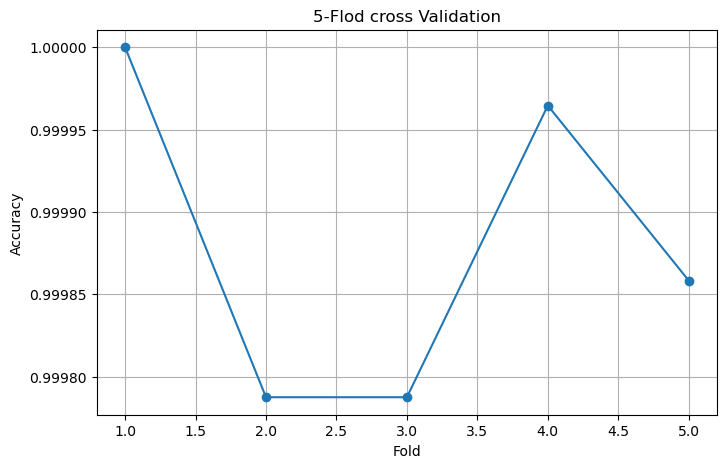

In [15]:
# Cross Validation Chart

plt.figure(figsize=(8,5))

plt.plot(
    range(1,6),
    rf_cv_scores,
    marker="o"
)
plt.title("5-Flod cross Validation")
plt.xlabel("Fold")
plt.ylabel("Accuracy")

plt.grid(True)
plt.show()

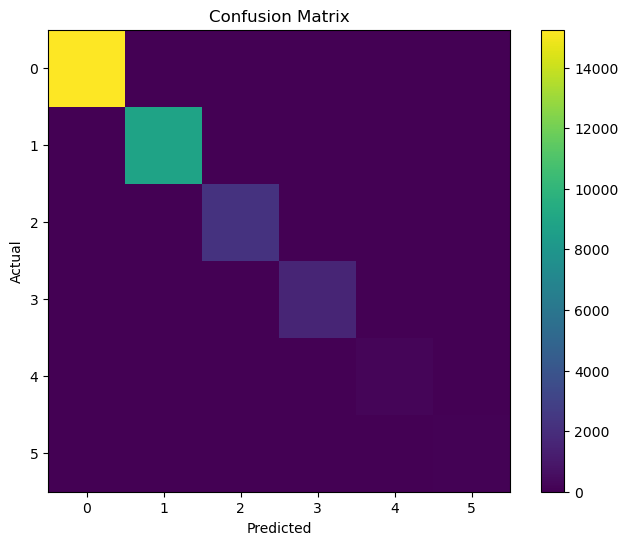

In [16]:
# Confusion Matrix

cm = confusion_matrix(
    y_test,
    rf_pred
)

plt.figure(figsize=(8,6))
plt.imshow(cm)

plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.colorbar()
plt.show()

In [17]:
# Classification Report
from sklearn.metrics import classification_report
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=[
            "Good",
            "Moderate",
            "USG",
            "Unhealthy",
            "Very Unhealthy",
            "Hazardous"
        ]
    )
)

                precision    recall  f1-score   support

          Good       1.00      1.00      1.00     15249
      Moderate       1.00      1.00      1.00      8817
           USG       1.00      1.00      1.00      2253
     Unhealthy       1.00      1.00      1.00      1579
Very Unhealthy       0.99      1.00      0.99       237
     Hazardous       1.00      0.98      0.99        89

      accuracy                           1.00     28224
     macro avg       1.00      1.00      1.00     28224
  weighted avg       1.00      1.00      1.00     28224



In [18]:
# Feature Importance

importance = rf_model.feature_importances_

features_importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})
features_importance_df = features_importance_df.sort_values(
    by= "Importance",
    ascending= False
)
print(features_importance_df)

                         Feature  Importance
5              air_quality_PM2.5    0.613038
6               air_quality_PM10    0.262110
7    air_quality_Carbon_Monoxide    0.048660
10   air_quality_Sulphur_dioxide    0.033137
8   air_quality_Nitrogen_dioxide    0.021212
1                       humidity    0.005564
0            temperature_celsius    0.004559
9              air_quality_Ozone    0.004381
2                       wind_kph    0.003127
4                      precip_mm    0.002108
3                    pressure_mb    0.002102


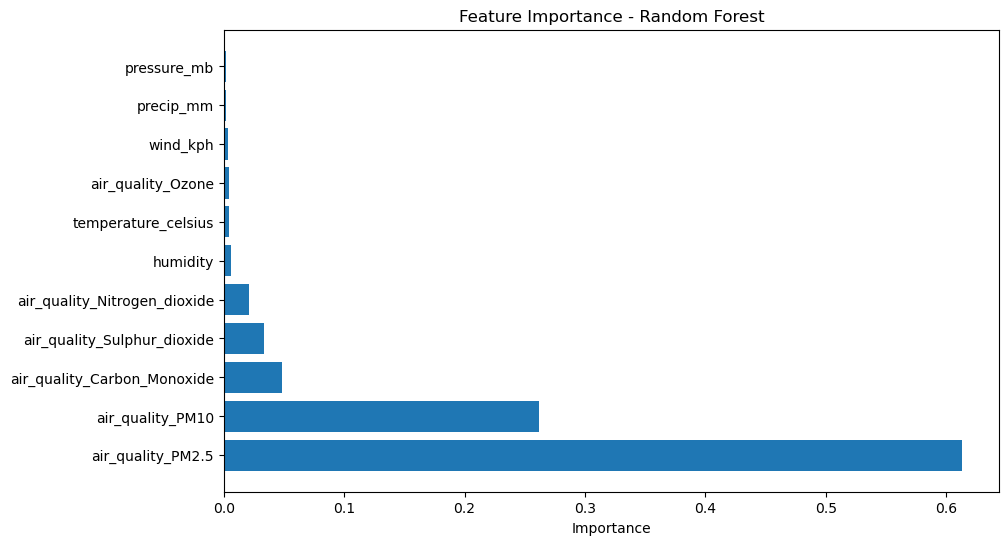

In [19]:
# Feature Importance Chart

plt.figure(figsize=(10,6))
plt.barh(
    features_importance_df["Feature"],
    features_importance_df["Importance"]
)
plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.show()

# SHAP Explainable AI

In [20]:
# Import SHAP

import shap
print("SHAP Imported Successfully")

SHAP Imported Successfully


In [21]:
# Create SHAP Explainer

explainer = shap.TreeExplainer(
    rf_model
)
print("SHAP Explainer Created")

SHAP Explainer Created


In [22]:
# Generate SHAP Values

shap_values = explainer.shap_values(
    x_test
)
print("SHAP Values Generated")

SHAP Values Generated


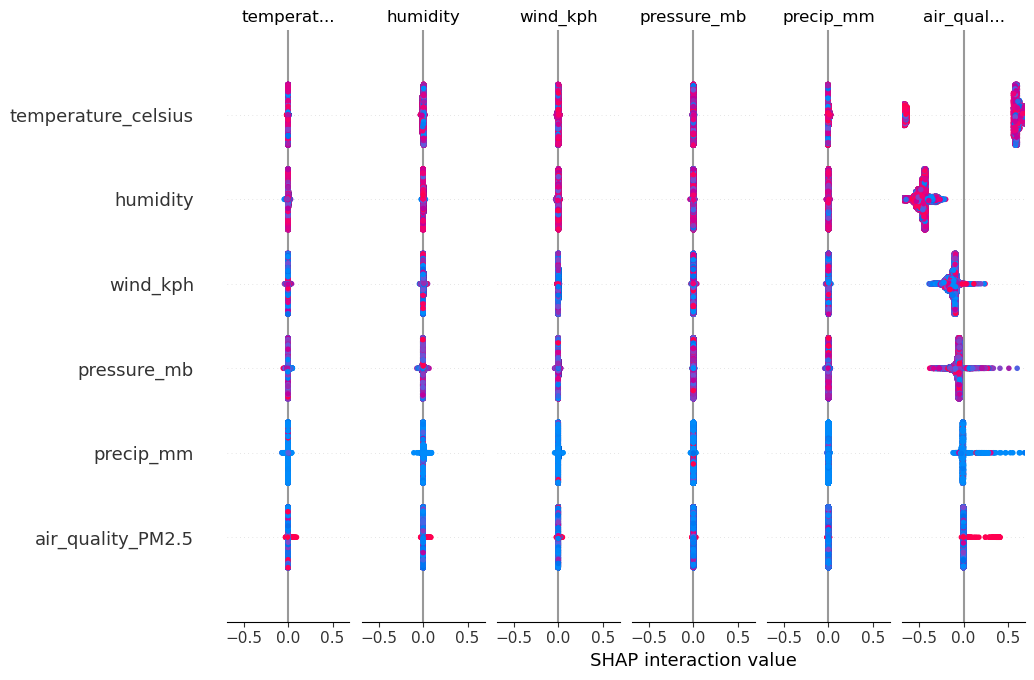

In [23]:
# SHAP Feature Importance

shap.summary_plot(
    shap_values,
    x_test
)

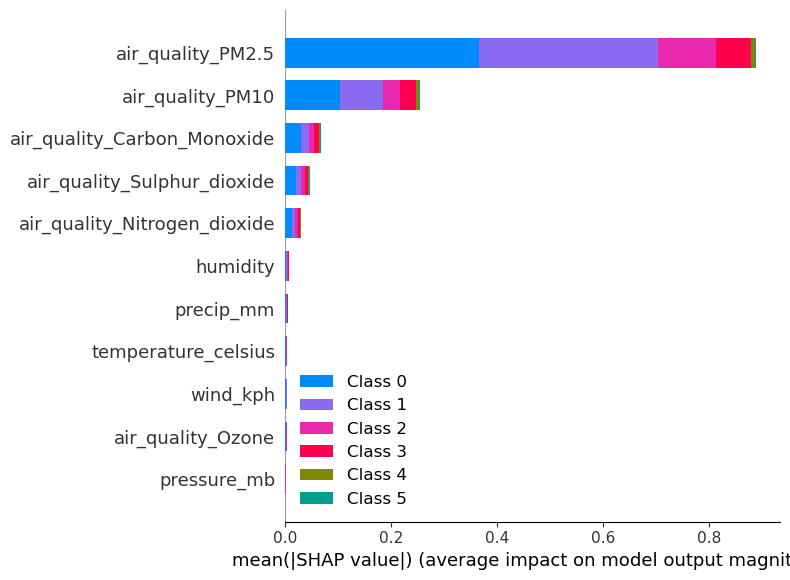

In [24]:
# SHAP Feature Importance Bar Plot

shap.summary_plot(
    shap_values,
    x_test,
    plot_type="bar"
)

In [29]:
# Save Random Forest

with open("../models/aqi_model.pkl", "wb") as file:
    pickle.dump(rf_model, file)
print("Random Forest saved successfully!")

Random Forest saved successfully!


# Conclusion

Four machine learning models were trained and evaluated for AQI prediction.

Random Forest achieved the best balance of performance and interpretability.

5-Fold Cross Validation confirmed model stability.

SHAP Explainable AI was used to identify the most influential pollutants affecting AQI prediction.

The trained model was integrated with FastAPI and React to create the AeroMind AI web application.